# Análisis de Componentes Principales: seis países y 167 países

Cuaderno del **Capítulo 2** de las notas. Reproduce los ejemplos del capítulo con datos de `Country-data.csv` (HELP International, Kaggle).

**Contenido**
1. Seis países: estandarización, matriz de correlaciones, eigenvalores y cargas
2. ¿Covarianzas o correlaciones? El efecto de las unidades
3. PCA mediante la SVD y la aproximación de rango uno
4. ¿Cuántos componentes? Kaiser y análisis paralelo
5. Aplicación: 167 países y 9 indicadores (biplot)
6. Inferencia: intervalo de Anderson para $\lambda_1$

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})

In [2]:
paises = pd.read_csv("../05 Clustering/04 Clustering Countries/Country-data.csv", index_col="country")
seis = ["Canada", "Chile", "Colombia", "Peru", "Bolivia", "Guatemala"]
V = ["child_mort", "income", "exports"]
X = paises.loc[seis, V]
X

,child_mort,income,exports
country,,,
Canada,5.6,40700,29.1
Chile,8.7,19400,37.7
Colombia,18.6,10900,15.9
Peru,20.3,9960,27.8
Bolivia,46.6,5410,41.2
Guatemala,35.4,6710,25.8


## 1. Seis países: matriz de correlaciones, eigenvalores y cargas

In [3]:
n, p = X.shape
Z = (X - X.mean()) / X.std(ddof=0)          # divisor n, como en las notas
R = Z.T @ Z / n
l, G = np.linalg.eigh(R.values)
l, G = l[::-1], G[:, ::-1]
G = G * np.sign(G[1])                        # ingreso con carga positiva
print("Z =\n", Z.round(3)); print("R =\n", R.round(3))
print("Eigenvalores:", l.round(3), "| proporción:", (l / p).round(3), "| acumulada:", (l.cumsum() / p).round(3))
print("Cargas G =\n", pd.DataFrame(G, index=V, columns=["CP1", "CP2", "CP3"]).round(3))
print("Verificación R g1 = l1 g1:", (R.values @ G[:, 0]).round(3), (l[0] * G[:, 0]).round(3))

Z =
            child_mort  income  exports
country                               
Canada         -1.176   2.078   -0.059
Chile          -0.961   0.321    0.987
Colombia       -0.273  -0.381   -1.664
Peru           -0.155  -0.458   -0.217
Bolivia         1.672  -0.834    1.413
Guatemala       0.894  -0.726   -0.460
R =
             child_mort  income  exports
child_mort        1.00  -0.770    0.260
income           -0.77   1.000    0.014
exports           0.26   0.014    1.000
Eigenvalores: [1.809 1.008 0.183] | proporción: [0.603 0.336 0.061] | acumulada: [0.603 0.939 1.   ]
Cargas G =
               CP1    CP2    CP3
child_mort -0.709  0.014  0.705
income      0.671  0.320  0.669
exports    -0.216  0.947 -0.236
Verificación R g1 = l1 g1: [-1.282  1.214 -0.391] [-1.282  1.214 -0.391]


In [4]:
corr = pd.DataFrame(G * np.sqrt(l), index=V, columns=["CP1", "CP2", "CP3"])
print("Correlaciones componente-variable:\n", corr.round(3))
print("Suma de cuadrados por fila (=1):", (corr**2).sum(axis=1).round(3).tolist())
print("Suma de cuadrados por columna (=l_k):", (corr**2).sum().round(3).tolist())
Y = pd.DataFrame(Z.values @ G, index=seis, columns=["CP1", "CP2", "CP3"])
Y.round(3)

Correlaciones componente-variable:
               CP1    CP2    CP3
child_mort -0.953  0.014  0.302
income      0.903  0.321  0.286
exports    -0.291  0.951 -0.101
Suma de cuadrados por fila (=1): [1.0, 1.0, 1.0]
Suma de cuadrados por columna (=l_k): [1.809, 1.008, 0.183]


,CP1,CP2,CP3
Canada,2.242,0.592,0.574
Chile,0.683,1.024,-0.696
Colombia,0.298,-1.702,-0.055
Peru,-0.151,-0.354,-0.365
Bolivia,-2.050,1.095,0.289
Guatemala,-1.022,-0.656,0.253


## 2. ¿Covarianzas o correlaciones?

Con $\mathbf{S}$, la variable con unidades más grandes (ingreso en dólares) domina el primer componente.

In [5]:
S = np.cov(X.T, ddof=0)
ls, Gs = np.linalg.eigh(S)
print("Varianzas:", np.diag(S).round(1))
print("Primer componente de S:", np.abs(Gs[:, -1]).round(4), "| proporción:", (ls[-1] / ls.sum()).round(6))

Varianzas: [2.072e+02 1.469e+08 6.760e+01]
Primer componente de S: [0.001 1.    0.   ] | proporción: 0.999999


## 3. PCA mediante la SVD y la aproximación de rango uno

In [6]:
U, dsv, Vt = np.linalg.svd(Z.values, full_matrices=False)
print("Valores singulares:", dsv.round(3), "| d²/n =", (dsv**2 / n).round(3))
Z1 = dsv[0] * np.outer(U[:, 0], Vt[0])
print("Error de rango uno ||Z - Z1||² =", ((Z.values - Z1)**2).sum().round(3), "= n(l2+l3) =", (n * l[1:].sum()).round(3))

Valores singulares: [3.294 2.46  1.047] | d²/n = [1.809 1.008 0.183]
Error de rango uno ||Z - Z1||² = 7.148 = n(l2+l3) = 7.148


## 4. ¿Cuántos componentes? Análisis paralelo

In [7]:
def analisis_paralelo(n, p, reps=5000, semilla=2026):
    rng = np.random.default_rng(semilla)
    sims = np.array([np.linalg.eigvalsh(np.corrcoef(rng.standard_normal((n, p)).T))[::-1]
                     for _ in range(reps)])
    return sims.mean(axis=0), np.percentile(sims, 95, axis=0)

media, p95 = analisis_paralelo(n, p)
print("Eigenvalores observados:", l.round(3))
print("Análisis paralelo, percentil 95:", p95.round(3))
print("Con n = 6, ningún eigenvalor supera al azar." if (l < p95).all() else "")

Eigenvalores observados: [1.809 1.008 0.183]
Análisis paralelo, percentil 95: [2.292 1.2   0.684]
Con n = 6, ningún eigenvalor supera al azar.


## 5. Aplicación: 167 países y 9 indicadores

Eigenvalores: [4.136 1.546 1.17  0.995 0.661 0.224 0.113 0.088 0.067]
Acumulada: [0.46  0.631 0.761 0.872 0.945 0.97  0.983 0.993 1.   ]
AP p95: [1.49  1.322 1.209 1.12  1.04  0.967 0.896 0.823 0.744]


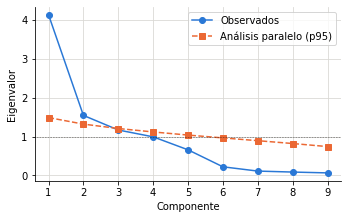

In [8]:
Zt = (paises - paises.mean()) / paises.std(ddof=0)
N, P = Zt.shape
lt, Gt = np.linalg.eigh((Zt.T @ Zt / N).values)
lt, Gt = lt[::-1], Gt[:, ::-1]
Gt = Gt * np.sign(Gt[paises.columns.get_loc("income")])
_, p95t = analisis_paralelo(N, P)
print("Eigenvalores:", lt.round(3)); print("Acumulada:", (lt.cumsum() / P).round(3)); print("AP p95:", p95t.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.2))
k = np.arange(1, P + 1)
ax.plot(k, lt, color=AZUL, marker="o", label="Observados")
ax.plot(k, p95t, color=NARANJA, ls="--", marker="s", label="Análisis paralelo (p95)")
ax.axhline(1, color=TINTA, lw=0.6, ls=":")
ax.set_xlabel("Componente"); ax.set_ylabel("Eigenvalor"); ax.legend(); plt.show()

              CP1    CP2
child_mort -0.853  0.240
exports     0.577  0.762
health      0.307 -0.302
imports     0.328  0.835
income      0.810  0.028
inflation  -0.393 -0.010
life_expec  0.866 -0.277
total_fer  -0.821  0.193
gdpp        0.798 -0.057
CP1 más bajos: {'Nigeria': -4.91, 'Haiti': -4.41, 'Central African Republic': -3.96, 'Chad': -3.56, 'Niger': -3.45}
CP1 más altos: {'Luxembourg': 6.92, 'Singapore': 5.78, 'Qatar': 4.24, 'Switzerland': 4.09, 'Norway': 3.72}


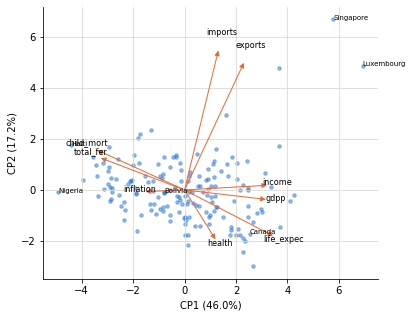

In [9]:
corr_t = pd.DataFrame(Gt[:, :2] * np.sqrt(lt[:2]), index=paises.columns, columns=["CP1", "CP2"])
print(corr_t.round(3))
Yt = pd.DataFrame(Zt.values @ Gt[:, :2], index=paises.index, columns=["CP1", "CP2"])
print("CP1 más bajos:", Yt.CP1.nsmallest(5).round(2).to_dict())
print("CP1 más altos:", Yt.CP1.nlargest(5).round(2).to_dict())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(Yt.CP1, Yt.CP2, s=12, color=AZUL, alpha=0.5)
esc = 0.8 * np.abs(Yt.values).max() / np.abs(Gt[:, :2]).max()
for j, v in enumerate(paises.columns):
    ax.annotate("", xy=(esc * Gt[j, 0], esc * Gt[j, 1]), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=NARANJA))
    ax.text(1.1 * esc * Gt[j, 0], 1.1 * esc * Gt[j, 1], v, fontsize=8, ha="center")
for c in ["Haiti", "Nigeria", "Luxembourg", "Singapore", "Canada", "Bolivia"]:
    ax.annotate(c, (Yt.loc[c, "CP1"], Yt.loc[c, "CP2"]), fontsize=7)
ax.set_xlabel(f"CP1 ({lt[0]/P:.1%})"); ax.set_ylabel(f"CP2 ({lt[1]/P:.1%})"); plt.show()

## 6. Inferencia: intervalo de Anderson (1963) para $\lambda_1$

$\hat\lambda_k/(1+z\sqrt{2/n}) \le \lambda_k \le \hat\lambda_k/(1-z\sqrt{2/n})$. Supone normalidad y está formulado para $\mathbf{S}$: tómese con cautela.

In [10]:
z = 1.96 * np.sqrt(2 / N)
print(f"IC95% para λ1: [{lt[0]/(1+z):.2f}, {lt[0]/(1-z):.2f}]")
# Ejercicio: construya un intervalo bootstrap remuestreando países y compárelo.

IC95% para λ1: [3.41, 5.26]
